<a href="https://colab.research.google.com/github/Mohanaprema/ML-Projects-samples/blob/main/WebAd_Optimization_using_Reinforcement_Learning_Upper_Confidence_Bound.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
from google.colab import files
uploaded=files.upload()


Saving dataset.csv to dataset.csv


In [3]:
ds=pd.read_csv('dataset.csv')
print(ds.head())
print(ds.shape)

   Ad 1  Ad 2  Ad 3  Ad 4  Ad 5  Ad 6  Ad 7  Ad 8  Ad 9  Ad 10
0     1     0     0     0     1     0     0     0     1      0
1     0     0     0     0     0     0     0     0     1      0
2     0     0     0     0     0     0     0     0     0      0
3     0     1     0     0     0     0     0     1     0      0
4     0     0     0     0     0     0     0     0     0      0
(10000, 10)


In [20]:
import math
observations=10000
no_of_ads=10
ads_selected=[]
no_of_selection_of_each_ads =[0]* no_of_ads
sums_of_reward_of_each_ads =[0]* no_of_ads
total_rewards=0
for n in range(0,observations):
   ad=0
   max_upper_bound=0
   for i in range(0,no_of_ads):
       if(no_of_selection_of_each_ads[i]>0):
          average_reward= sums_of_reward_of_each_ads[i]/no_of_selection_of_each_ads[i]
          delta_i= math.sqrt(3/2*math.log(n+1)/no_of_selection_of_each_ads[i])
          upper_bound= average_reward + delta_i
       else:
            upper_bound=1e400
       if upper_bound> max_upper_bound:
            max_upper_bound=upper_bound
            ad=i
   ads_selected.append(ad)
   no_of_selection_of_each_ads[ad] = no_of_selection_of_each_ads[ad]+1
   reward=int(ds.values[n,ad])
   sums_of_reward_of_each_ads[ad]=sums_of_reward_of_each_ads[ad]+reward
   total_rewards=total_rewards+reward
print('Rewards by ads ', sums_of_reward_of_each_ads)
print('Total Rewards ',total_rewards)
print('Ads selected ', ads_selected)





Rewards by ads  [120, 47, 7, 38, 1675, 1, 27, 236, 20, 7]
Total Rewards  2178
Ads selected  [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 0, 1, 2, 3, 4, 5, 6, 7, 8, 8, 9, 0, 8, 1, 2, 3, 4, 5, 6, 6, 7, 7, 7, 9, 7, 0, 6, 8, 1, 2, 3, 4, 4, 4, 4, 4, 5, 9, 7, 0, 0, 6, 8, 4, 0, 7, 1, 1, 2, 3, 5, 9, 4, 1, 6, 8, 0, 7, 2, 3, 5, 9, 4, 1, 6, 8, 0, 7, 7, 7, 7, 7, 7, 4, 2, 3, 5, 9, 1, 6, 8, 0, 0, 7, 0, 4, 1, 6, 8, 2, 3, 5, 9, 7, 0, 4, 4, 4, 7, 7, 7, 7, 1, 6, 8, 2, 3, 5, 9, 0, 7, 7, 4, 7, 7, 7, 1, 6, 8, 0, 4, 4, 2, 3, 5, 9, 4, 7, 0, 7, 1, 1, 1, 6, 6, 6, 6, 6, 8, 4, 2, 3, 5, 9, 7, 7, 7, 0, 6, 4, 1, 1, 1, 8, 7, 2, 3, 5, 9, 4, 0, 1, 1, 1, 6, 7, 8, 4, 1, 2, 3, 5, 9, 0, 6, 7, 8, 4, 7, 1, 0, 6, 2, 3, 5, 9, 7, 7, 7, 7, 4, 4, 4, 4, 4, 7, 8, 1, 0, 6, 6, 6, 7, 4, 2, 3, 5, 9, 1, 6, 8, 7, 0, 4, 4, 4, 4, 4, 2, 3, 5, 9, 1, 6, 7, 4, 8, 0, 7, 4, 4, 4, 1, 6, 2, 3, 5, 9, 0, 0, 0, 7, 8, 4, 0, 0, 0, 1, 6, 7, 4, 2, 3, 5, 9, 0, 8, 7, 1, 6, 4, 0, 7, 7, 7, 7, 7, 2, 3, 5, 9, 8, 4, 1, 6, 6, 6, 7, 7, 7, 0, 6

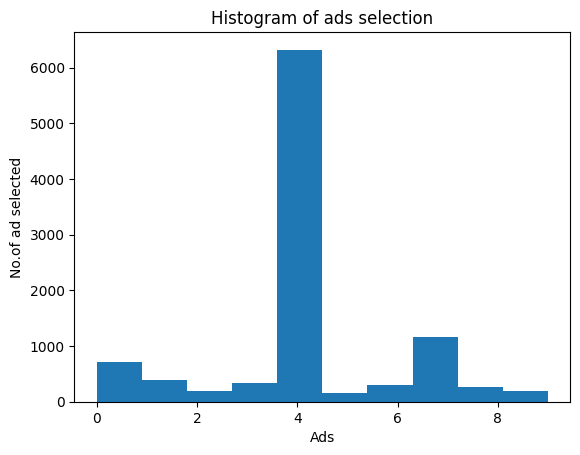

In [17]:
plt.hist(ads_selected)
plt.title('Histogram of ads selection')
plt.xlabel('Ads')
plt.ylabel('No.of ad selected')
plt.show()
